# Weekly forecast review

One weekly review, end to end, on synthetic data: **signals → rule engine → investigator → refuter → decision**.

Every week, for every item at every retailer, the question is the same: raise the forecast, cut it, hold it, or leave it alone. Cutting too far empties shelves; raising without cause traps cash in stock. The two mistakes do not cost the same, so they do not share a rule.

> Clean-room version. Written from scratch on generated data with illustrative parameters. No code, data or thresholds from any employer. See `forecast_review/synthetic.py` for how the data is made.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd

from forecast_review import pipeline, report, synthetic
from forecast_review.plots import planted_scenarios
from forecast_review.synthetic import AS_OF

pd.set_option("display.max_colwidth", 100)
weekly, plan = synthetic.generate(seed=7)
print(f"{weekly['retailer'].nunique()} retailers · {weekly['sku'].nunique()} items · "
      f"{weekly['week'].nunique() - 1} complete weeks + 1 unfinished week · review date {AS_OF:%Y-%m-%d}")

5 retailers · 60 items · 104 complete weeks + 1 unfinished week · review date 2026-06-26


## 1. Run the review

The rule engine flags items and proposes an action. For each flagged item, the investigator states what the flag implies as a claim, and the refuter tries to disprove it. A refuted change does not ship; a suspect one goes to a planner.

In [2]:
rows = pipeline.review(weekly, plan, AS_OF)
print(report.summary(rows))

decisions = pipeline.to_frame(rows)
flagged = decisions[decisions["verdict"] != ""]
flagged[["retailer", "sku", "scenario", "proposed", "verdict", "final", "change", "buffer", "to_planner"]]

60 items · 12 flagged · 3 claims refuted · 1 sent to planner
RAISE 3 · LOWER 5 · HOLD 4 · OK 48


,retailer,sku,scenario,proposed,verdict,final,change,buffer,to_planner
2,RETAILER_A,A-03,supply_gap,HOLD,REFUTED,HOLD,0.000,0.08,False
6,RETAILER_A,A-07,real_decline,LOWER,CONFIRMED,LOWER,-0.200,0.00,False
13,RETAILER_B,B-02,confirmed_growth,RAISE,CONFIRMED,RAISE,0.277,0.00,False
19,RETAILER_B,B-08,,RAISE,CONFIRMED,RAISE,0.228,0.00,False
20,RETAILER_B,B-09,bulk_order,HOLD,REFUTED,HOLD,0.000,0.00,False
25,RETAILER_C,C-02,,RAISE,CONFIRMED,RAISE,0.168,0.00,False
28,RETAILER_C,C-05,spike_baseline,LOWER,REFUTED,HOLD,0.000,0.00,False
29,RETAILER_C,C-06,,LOWER,CONFIRMED,LOWER,-0.156,0.00,False
36,RETAILER_D,D-01,new_item,HOLD,SUSPECT,HOLD,0.000,0.00,True
43,RETAILER_D,D-08,,LOWER,CONFIRMED,LOWER,-0.154,0.00,False


## 2. The six planted scenarios

The generator hides six situations among ordinary noise, each built to test one rule. The shaded bands are the two four-week windows the rules compare. Store in-stock is a different unit from units sold, so it is reported under each title rather than on a second axis.

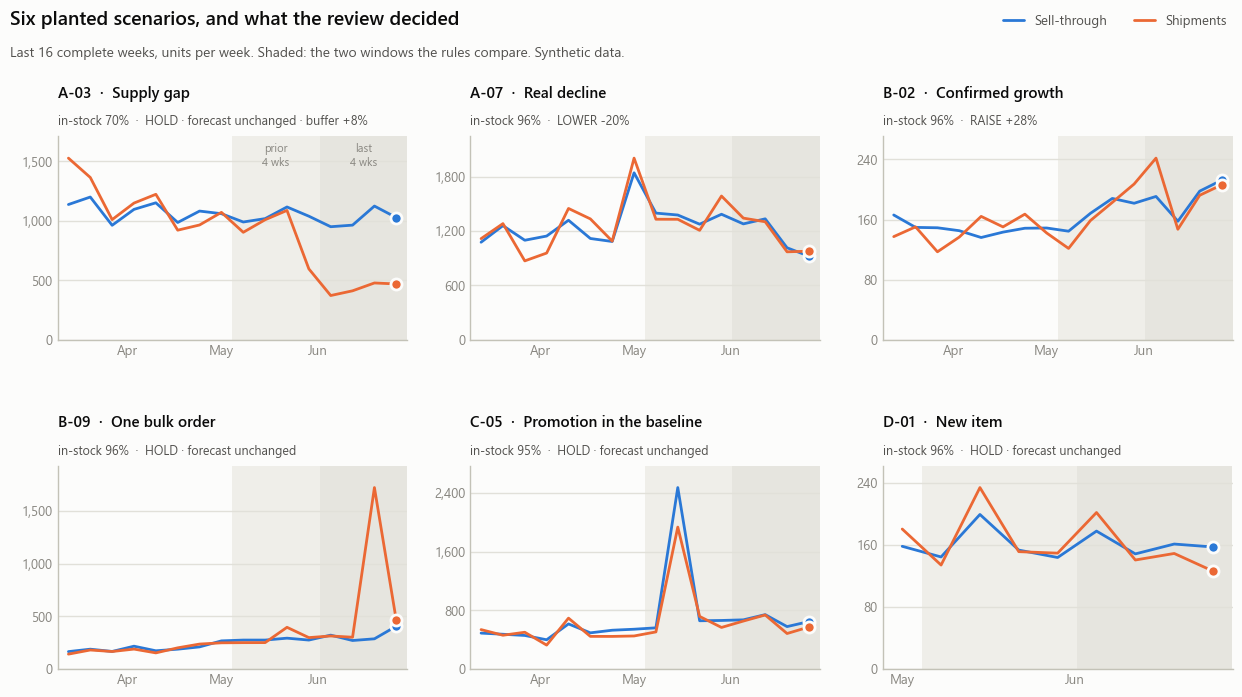

In [3]:
planted_scenarios(weekly, rows, AS_OF, path=ROOT / "images" / "planted_scenarios.png");

## 3. Three traces

Every flagged item gets a trace: the flag, the checks behind it, what the rules proposed, what the refuter said, and the final decision.

- **A-03, a supply gap.** Shipments halved and a simple rule would cut. Sell-through held and store shelves are emptying: the fall is in supply, not demand.
- **C-05, a promotion in the baseline.** The rules proposed a 20% cut on a 46% "drop". The refuter took the spike week out, and the drop went with it.
- **B-02, confirmed growth.** Two independent signals agree, so the raise goes through, capped.

In [4]:
by_sku = {r.signals.sku: r for r in rows}
for sku in ("A-03", "C-05", "B-02"):
    print(report.trace(by_sku[sku]), end="\n\n")

ITEM      RETAILER_A · A-03 · everyday
FLAG      shipments -51% vs the prior 4 weeks
CHECK     sell-through, last 4 weeks ........    +0%  flat
CHECK       same, spike weeks removed .......    +0%
CHECK     store-level in-stock ..............    70%  <- below floor
CHECK     shipments, last 4 weeks ...........   -51%
CHECK     open orders .......................    +2%  flat
CHECK     history ........................... 104 weeks
RULE      proposed HOLD: shipments -51% while sell-through held and in-stock is below the floor: a supply gap
REFUTE    "demand fell": REFUTED. flat sell-through with in-stock at 70% indicates a supply gap, not a demand drop
VERDICT   HOLD · forecast unchanged · buffer +8%

ITEM      RETAILER_C · C-05 · summer
FLAG      sell-through -46% vs the prior 4 weeks
CHECK     sell-through, last 4 weeks ........   -46%  down
CHECK       same, spike weeks removed .......    -7%  one week dominates the window
CHECK     store-level in-stock ..............    95%
CHECK    

## 4. What the refuter changed

Items where the rules proposed a change and the refuter stopped it, with the forecast units the change would have moved over the next six months.

In [5]:
six_months = plan.groupby(["retailer", "sku"])["forecast_units"].sum()
stopped = [r for r in rows if r.proposal.action != r.final.action]
pd.DataFrame([{
    "item": f"{r.signals.retailer} {r.signals.sku}",
    "proposed": f"{r.proposal.action} {r.proposal.change:+.0%}",
    "final": r.final.action,
    "units the change would have moved": round(abs(r.proposal.change) * six_months[(r.signals.retailer, r.signals.sku)]),
    "why": r.verdict.reason,
} for r in stopped])

,item,proposed,final,units the change would have moved,why
0,RETAILER_C C-05,LOWER -20%,HOLD,2537,"one spike week sits in the comparison window; on run-rate, sell-through is -7%"


## 5. The revised plan

Each final decision applied to every future month of the plan, summed by retailer.

In [6]:
revised = pipeline.revised_plan(rows, plan)
by_retailer = revised.groupby("retailer")[["forecast_units", "revised_units"]].sum().round(0)
by_retailer["change"] = (by_retailer["revised_units"] / by_retailer["forecast_units"] - 1).map("{:+.1%}".format)
by_retailer

,forecast_units,revised_units,change
retailer,,,
RETAILER_A,434632.0,430572.0,-0.9%
RETAILER_B,175100.0,178955.0,+2.2%
RETAILER_C,112836.0,111899.0,-0.8%
RETAILER_D,50367.0,49813.0,-1.1%
RETAILER_E,29912.0,29194.0,-2.4%


## Key findings

- Most items need nothing: the review is quiet by design, and the interesting part is the handful it flags.
- All six planted scenarios land where the rules intend: the supply gap is held with a buffer, the real decline is cut and capped, confirmed growth is raised, the bulk order is ignored, the new item is protected and sent to a planner.
- The one change the refuter stopped is the promotion in the baseline. Without that separate role, a stable item would have been cut on a spike.
- The data is synthetic. These results show that the design behaves as intended, not how accurate any real forecast is.